# Where cells sit in the cycle

A knockout that stalls the cell cycle changes how much DNA its cells hold. This tutorial shows how to place single
cells on the cycle with {func}`~mantispy.tl.fit_cell_cycle` and {func}`~mantispy.tl.project_cell_cycle`, and how
to read what they write. [How the cell-cycle model works](cell_cycle_method.ipynb) explains each step of the model.

What you can learn depends on what you measured:

| What you measured | What you get | How |
| --- | --- | --- |
| a DNA stain | each cell's phase probabilities, a position for S cells, the population prior for G1 and G2M cells, and the cells below 2N or above 4N | {func}`~mantispy.tl.fit_cell_cycle`, {func}`~mantispy.tl.project_cell_cycle` |
| other channels that change through the cycle | an experimental order of the cells within a phase | {func}`~mantispy.tl.phase_order` |
| a marker of a phase, or a paired modality | a check of that order, and a split of G2M into G2 and mitosis | your own comparison |

The cells come from an optical pooled CRISPR screen in HeLa cells ({func}`~mantispy.ds.aconcagua_cells`). They are
the cells of eight genes and the non-targeting controls, imaged in four channels: DAPI for DNA, gamma-H2AX for DNA
damage, phalloidin for actin, and alpha-tubulin. Each gene's function predicts a place in the cycle, so we
state the predictions before looking:

| Gene | Function | Prediction |
| --- | --- | --- |
| RRM1 | makes the nucleotides DNA replication needs | more cells in S |
| HAUS6, SKA2 | build and attach the mitotic spindle | more cells in G2M |
| DTL | stops DNA from being copied twice in one cycle | more cells above 4N |
| PSMB7 | a proteasome subunit, without which cells pile up before and in mitosis | more cells in G2M |
| SF3B3 | a spliceosome subunit, whose loss stalls cells both in G1 and at G2 and M | more cells in G2M |
| ITGAV, TLN1 | cell adhesion, with no known direct role in the cycle | the same as the controls |

The [optical pooled screens case study](../../case_studies/optical_pooled_screens.ipynb) puts these genes in the
context of the whole screen.

## What the input needs

- The integrated intensity of a DNA stain, such as DAPI or Hoechst, per nucleus. It must be raw, since a normalized
  feature no longer doubles from G1 to G2. A pipeline that measured the image background should subtract it first.
- Reference cells that cycle in steady state, normally the negative controls.
- Groups within which the stain reads the same, to find the G1 peak in: the well in a pooled screen, where every well
  holds controls, or the plate in an arrayed screen.
- Optionally, the nuclear area and solidity, for the shape checks.
- Optionally, other channels for an order within a phase, and a marker to check it against.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import mantispy as mt

plt.rcParams["figure.dpi"] = 110

cells = mt.ds.aconcagua_cells()
print(cells.var["channel"].str.split("|").explode().value_counts().rename("features per channel").to_dict())
cells.obs["Metadata_Gene"].value_counts().rename("cells").to_frame().T

{'GH2AX': 355, 'DAPI': 353, 'PHALLOIDIN': 353, 'TUBULIN': 353}


Metadata_Gene,nontargeting,TLN1,SF3B3,HAUS6,ITGAV,PSMB7,RRM1,DTL,SKA2
cells,24166,2049,1984,1969,1921,1903,1890,1830,962


## From the DNA stain alone

### DNA content

{func}`~mantispy.tl.dna_content` turns the integrated DAPI intensity into DNA content in doublings, the log2 of the
intensity over that of the G1 peak. A G1 nucleus sits near 0, and a nucleus with twice that DNA sits near 1. We call
the two amounts 2N and 4N, as is usual for the G1 and G2 DNA content, although HeLa cells are hypertriploid.

Staining differs between wells, so in a pooled screen the G1 peak is found per well, and ``reference="negcon"`` finds
it on the non-targeting cells alone. A knockout that empties G1 then cannot move the peak of its well. In an arrayed
screen, where a well holds one treatment, the controls of each plate set its peak instead:

```python
mt.tl.dna_content(cells, dna_feature=..., by="Metadata_Plate", reference="negcon")
```

In [2]:
mt.tl.dna_content(
    cells,
    dna_feature="Nuclei_Intensity_IntegratedIntensity_DAPI",
    by=("Metadata_Plate", "Metadata_Well"),
    reference="negcon",
)

### Fitting the cycle on the controls

{func}`~mantispy.tl.fit_cell_cycle` checks that the controls cycle, then fits a G1 peak, S cells and a G2M peak to
their DNA content, with a flat background for cells off the cycle. [How the model works](cell_cycle_method.ipynb#the-template)
gives its assumptions. With ``qc_features``, it also learns shape cutoffs from the controls, used further down.

In [3]:
mt.tl.fit_cell_cycle(cells, reference="negcon", qc_features=("Nuclei_AreaShape_Area", "Nuclei_AreaShape_Solidity"))
model = cells.uns["mantispy"]["cell_cycle"]
print("share of the cycle in G1, S and G2M:", np.round(np.diff(model["edges"]), 2))
pd.Series(
    {
        "passed the check": model["passed"],
        "2N peak (doublings)": round(model["peaks"][0], 3),
        "4N peak (doublings)": round(model["peaks"][1], 3),
        "2N peak width (doublings)": round(model["sd"], 3),
        "share of cells in G1": round(model["fractions"][0], 2),
        "share of cells in S": round(model["fractions"][1], 2),
        "share of cells in G2M": round(model["fractions"][2], 2),
        "share of cells off the cycle": round(model["off_cycle"], 3),
    }
)

share of the cycle in G1, S and G2M: [0.57 0.3  0.14]


passed the check                 True
2N peak (doublings)            -0.005
4N peak (doublings)              0.92
2N peak width (doublings)       0.096
share of cells in G1             0.65
share of cells in S              0.25
share of cells in G2M             0.1
share of cells off the cycle    0.023
dtype: object

The controls pass the check. Their 2N peak sits at -0.005 doublings and their 4N peak at 0.92, short of 1. One
cause is an image background that was not subtracted, as [how the model works](cell_cycle_method.ipynb#the-input-dna-content)
shows. Of the control cells on the cycle, 65% are in G1, 25% in S and 10% in G2M, and 2.3% of all control cells sit
off the cycle. Converted with the age distribution of a growing population, the three shares become 57%, 30% and 14%
of the cycle, kept in ``model["edges"]``. A position is a fraction of the cycle, not a time in hours.

{func}`~mantispy.tl.project_cell_cycle` places every cell, knockouts included, on the controls' model. It writes:

- ``obsm["cell_cycle_probabilities"]``: the probability of G1, S, G2M, sub-2N and above-4N;
- ``obs["cell_cycle_phase"]``: the most probable of the five, a convenience for counting;
- ``obs["cell_cycle_position"]`` and ``obsm["cell_cycle_quantiles"]``: the median of the posterior position and its
  5%, 25%, 75% and 95% quantiles, for cells on the cycle;
- ``obs["cell_cycle_qc"]``: the shape checks, further down;
- ``uns["mantispy"]["cell_cycle_wells"]``: a check of each well's stain, further down.

In [4]:
mt.tl.project_cell_cycle(cells)
example = cells.obs.groupby("cell_cycle_phase", observed=True).head(1).index
pd.concat(
    [
        cells.obs.loc[example, ["Metadata_DNAContent", "cell_cycle_phase"]],
        cells.obsm["cell_cycle_probabilities"].loc[example],
        cells.obsm["cell_cycle_quantiles"].loc[example],
    ],
    axis=1,
).round(2)

,Metadata_DNAContent,cell_cycle_phase,G1,S,G2M,sub-2N,above-4N,5%,25%,50%,75%,95%
0,0.14,G1,0.79,0.20,0.00,0.00,0.00,0.03,0.16,0.33,0.53,0.62
1,0.27,S,0.13,0.85,0.00,0.02,0.00,0.18,0.61,0.63,0.65,0.68
3,1.00,G2M,0.00,0.18,0.81,0.00,0.01,0.83,0.87,0.91,0.96,0.99
5,1.45,above-4N,0.00,0.00,0.00,0.00,1.00,NaN,NaN,NaN,NaN,NaN
205,-0.84,sub-2N,0.00,0.00,0.00,1.00,0.00,NaN,NaN,NaN,NaN,NaN


The warning names the two wells the stain check could not judge, and why. The checks further down come back to them.

In the table, a cell at 0.14 doublings is in G1 with probability 0.79 and in S with 0.20, since a cell early in S
holds little more DNA than one in G1. A cell at 0.27 doublings is in S with probability 0.85, and the middle half of
its posterior spans 0.61 to 0.65 of the cycle. A cell at 1.00 doublings is in G2M with probability 0.81, and the
middle half of its posterior spans 0.87 to 0.96, most of G2M. The cells at 1.45 and -0.84 doublings sit above 4N and
below 2N, and have no position.

So the position means something per cell only in S. Within G1 and G2M it is the population prior, as
[the posterior for one cell](cell_cycle_method.ipynb#the-posterior-for-one-cell) shows. Don't correlate it with
morphology inside those phases.

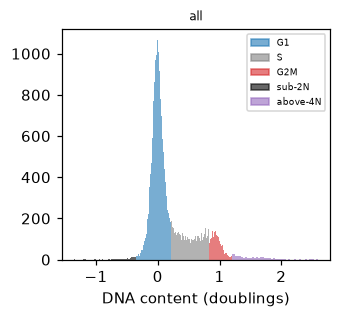

cell_cycle_phase
G1          0.670
S           0.196
G2M         0.120
above-4N    0.011
sub-2N      0.004
Name: proportion, dtype: float64

In [5]:
controls = cells[cells.obs["Metadata_Control_Type"] == "negcon"]
mt.pl.cell_cycle(controls, dna_feature="Metadata_DNAContent", by=None)
plt.gca().set_xlabel("DNA content (doublings)")
plt.show()
controls.obs["cell_cycle_phase"].value_counts(normalize=True).round(3)

Counted by their most probable phase, 67% of control cells are in G1, 20% in S, 12% in G2M, 1.1% above 4N and
0.4% below 2N. The counted shares differ a little from the fitted ones, since the most probable phase gives some early S cells
to G1 and some late S cells to G2M.

### The cell-cycle clock

{func}`~mantispy.pl.cell_cycle_clock` draws the placement as a ring, with position 0 at the top. Each cell's angle is
a position drawn from its posterior, so the ring fills. The S arc places each cell from its own DNA, and the G1 and
G2M arcs are shaded and labeled as the population prior.

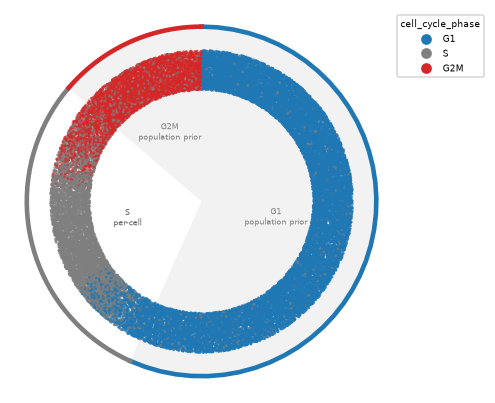

In [6]:
mt.pl.cell_cycle_clock(cells)

The same placement reads as a density with ``kind="rings"``. The drawn positions are smoothed into one curve over
every cell, filled by phase, and the dashed circle marks the height the curve would have if the cells spread evenly
over the cycle. The smoothing wraps across division, so the end of G2M runs into the start of G1.

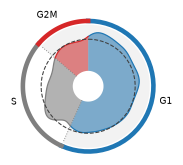

In [7]:
mt.pl.cell_cycle_clock(cells, kind="rings")

The curve rises above the dashed circle early in G1 and falls back to it late in G1, because the population prior
puts a cell early in G1 more often than late. Within the G1 and G2M arcs the shape comes from the prior, not from the
cells, so read how much of the curve sits in each arc rather than its shape there. The S arc places each cell from
its own DNA.

### Shape checks

With ``qc_features``, ``obs["cell_cycle_qc"]`` gives the first shape check a nucleus fails, with cutoffs learned
from the controls ([why](cell_cycle_method.ipynb#off-the-cycle-and-nuclei-that-are-not-single-cells)):

- ``"irregular"``: a solidity, the nucleus' area over that of its convex hull, below the controls';
- ``"small"``: an area below the controls';
- ``"dim"``: too little DNA per area;
- ``"ok"``: none of these.

Mitotic cells condense their chromosomes, so they can fail the same checks as merged nuclei and fragments.
Whether to drop flagged cells depends on the cell line and the question, and ``checks=`` in
{func}`~mantispy.tl.project_cell_cycle` picks the checks to apply. The screen's image classifier, whose interphase and
mitotic calls are in ``Metadata_Class``, shows what the flags catch in these HeLa cells.

In [8]:
mitotic = cells.obs["Metadata_Class"] == "Mitotic"
pd.crosstab(cells.obs["cell_cycle_qc"], np.where(mitotic, "mitotic", "interphase"), normalize="columns").round(3)

col_0,interphase,mitotic
cell_cycle_qc,,
ok,0.982,0.458
irregular,0.016,0.410
small,0.001,0.132
dim,0.000,0.000


The checks pass 98% of interphase cells but flag 54% of the cells the classifier calls mitotic, 41% as irregular
and 13% as small. Dropping flagged cells here would remove about half of the mitoses, so the rest of the tutorial keeps
every cell.

### Effects of the knockouts

The DNA content of each gene's cells, colored by phase, shows the effects before any test.

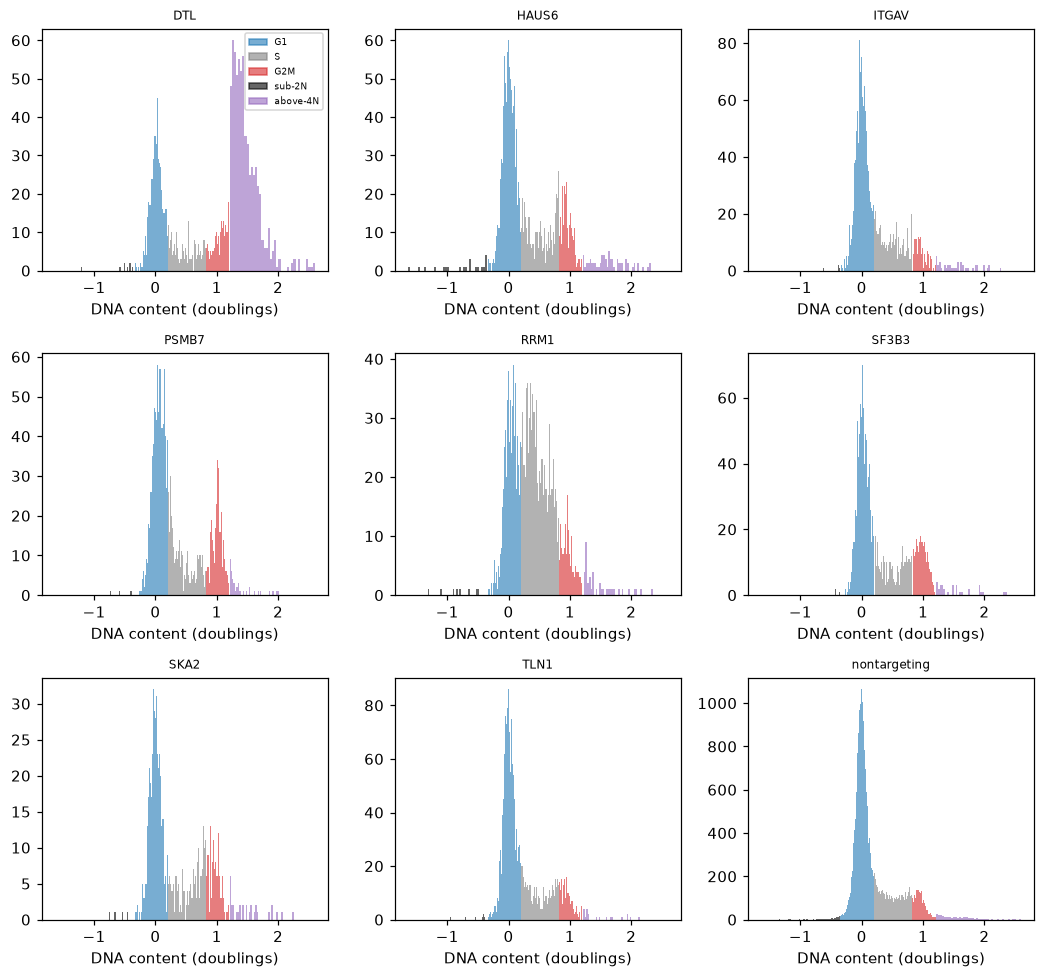

In [9]:
mt.pl.cell_cycle(cells, dna_feature="Metadata_DNAContent", by="Metadata_Gene", ncols=3)
for axis in plt.gcf().axes:
    axis.set_xlabel("DNA content (doublings)")
plt.show()

RRM1 has more cells in S, DTL more above 4N, and PSMB7 and SF3B3 a higher 4N peak. HAUS6 adds some cells above 4N as
well as at 4N, while ITGAV and TLN1 look like the controls.

{func}`~mantispy.tl.composition_shift` tests each gene's phase shares against the controls'. It compares shares within
each well of each plate and takes the guide as the unit. The p-value comes from relabeling whole guides, since cells
of one guide share the guide's efficiency and are not independent. With 999 permutations, a p-value cannot go below
0.001, and four guides per gene limit how small an effect the test can find.

In the first table, the gain is the change in the share of cells whose most probable phase is the predicted one, and
the expected gain counts each cell by its probabilities instead. The distance is the total variation distance over
all five phases. A prediction holds when the q-value is below 0.05 and the predicted phase gains more than 5
percentage points. For ITGAV and TLN1 it holds when the q-value is 0.05 or more. The second table gives the change in
every phase.

In [10]:
mt.tl.composition_shift(
    cells, key="cell_cycle_phase", groupby="Metadata_Gene", replicate="Metadata_Guide", n_permutations=999
)
shift = cells.uns["mantispy"]["composition_shift"].set_index("group")
gene = cells.obs["Metadata_Gene"].astype(str).to_numpy()
soft = cells.obsm["cell_cycle_probabilities"].groupby(gene).mean()
soft_change = soft - soft.loc["nontargeting"]

predicted = {
    "RRM1": "S",
    "HAUS6": "G2M",
    "SKA2": "G2M",
    "DTL": "above-4N",
    "PSMB7": "G2M",
    "SF3B3": "G2M",
    "ITGAV": None,
    "TLN1": None,
}
rows = []
for name, phase in predicted.items():
    significant = shift.loc[name, "qvalue"] < 0.05
    rows.append(
        {
            "gene": name,
            "predicted phase": phase or "no change",
            "gain in that phase": shift.loc[name, phase] if phase else np.nan,
            "expected gain": soft_change.loc[name, phase] if phase else np.nan,
            "distance": shift.loc[name, "distance"],
            "qvalue": shift.loc[name, "qvalue"],
            "holds": bool(significant and shift.loc[name, phase] > 0.05) if phase else not significant,
        }
    )
pd.DataFrame(rows).set_index("gene").round(3)

,predicted phase,gain in that phase,expected gain,distance,qvalue,holds
gene,,,,,,
RRM1,S,0.278,0.255,0.322,0.003,True
HAUS6,G2M,0.097,0.078,0.135,0.024,True
SKA2,G2M,0.108,0.090,0.152,0.003,True
DTL,above-4N,0.352,0.347,0.414,0.003,True
PSMB7,G2M,0.136,0.108,0.146,0.010,True
SF3B3,G2M,0.115,0.092,0.120,0.036,True
ITGAV,no change,NaN,NaN,0.033,0.420,True
TLN1,no change,NaN,NaN,0.034,0.420,True


In [11]:
shift[["G1", "S", "G2M", "sub-2N", "above-4N"]].round(3)

,G1,S,G2M,sub-2N,above-4N
group,,,,,
PSMB7,-0.137,-0.008,0.136,-0.001,0.010
DTL,-0.332,-0.082,0.061,0.001,0.352
SF3B3,-0.110,-0.009,0.115,-0.001,0.005
SKA2,-0.152,0.018,0.108,0.000,0.025
HAUS6,-0.135,0.009,0.097,0.006,0.024
ITGAV,-0.027,0.021,-0.006,-0.000,0.012
TLN1,-0.033,0.007,0.027,-0.000,-0.001
RRM1,-0.322,0.278,0.032,0.001,0.010


Every predicted gain is significant, and ITGAV and TLN1 show no significant change. RRM1 gains 28 percentage
points of its cells in S, and DTL gains 35 above 4N. HAUS6, SKA2, PSMB7 and SF3B3 gain 10 to 14 points in G2M, with
q-values from 0.003 to 0.036. ITGAV and TLN1 sit at a total variation distance of 0.03 from the controls, with
q-values of 0.42. No change was found, which does not show that there is none.

SF3B3's G1 share falls by 11 points rather than rising, so of the stall in G1 and at G2 and M that its function
predicts, only the G2 and M part shows. The PSMB7 cells imaged are those that survived losing the proteasome, so its
shares may understate the arrest.

The guides of a gene should agree. The table gives each guide's share of cells per phase.

In [12]:
per_guide = pd.crosstab(
    [cells.obs["Metadata_Gene"], cells.obs["Metadata_Guide"]], cells.obs["cell_cycle_phase"], normalize="index"
)
per_guide.drop(index="nontargeting", level=0).round(2)

cell_cycle_phase                G1     S   G2M  sub-2N  above-4N
Metadata_Gene Metadata_Guide                                    
DTL           ACAGCTGTATT     0.27  0.09  0.22    0.00      0.42
              AGGTGATAAAC     0.47  0.14  0.17    0.01      0.21
              TGAAGCTGCCT     0.31  0.11  0.16    0.01      0.41
              TTTCCAGCAAA     0.30  0.14  0.14    0.00      0.42
HAUS6         AAATTATATGA     0.33  0.22  0.36    0.03      0.06
              AACTTGAGATC     0.62  0.20  0.15    0.00      0.02
              ATGCATTTGTG     0.58  0.20  0.18    0.01      0.03
              CTGATTCCTTA     0.51  0.22  0.22    0.01      0.03
ITGAV         AACGATGAGCT     0.69  0.20  0.10    0.00      0.01
              AAGTTACTTCG     0.65  0.21  0.11    0.01      0.03
              AGAACATGACT     0.63  0.21  0.12    0.00      0.04
              GCACCTCTCTT     0.62  0.24  0.12    0.00      0.02
PSMB7         AACTGGCACGA     0.40  0.23  0.33    0.00      0.04
              GAAAACGTTAC     0.48  0.21  0.28    0.00      0.03
              GCAGATACAAG     0.62  0.15  0.21    0.01      0.01
              TAAGTTGCCTT     0.54  0.19  0.25    0.00      0.02
RRM1          CCTACCTAGAA     0.29  0.48  0.20    0.00      0.02
              CTTGTACCCCA     0.32  0.52  0.13    0.00      0.03
              GTAATCCAAGG     0.31  0.55  0.11    0.01      0.02
              TGGCAAACACT     0.43  0.38  0.16    0.01      0.02
SF3B3         AAGAATAGCTC     0.43  0.18  0.38    0.00      0.02
              AGCAGACAATG     0.66  0.17  0.16    0.01      0.01
              CCACAGGCCAC     0.44  0.23  0.31    0.00      0.02
              TGAGCCGGATC     0.52  0.18  0.28    0.00      0.01
SKA2          CAACAGCAACT     0.47  0.26  0.23    0.00      0.03
              GGATTACATTC     0.52  0.21  0.25    0.01      0.01
              GGTCGATAAGC     0.50  0.17  0.32    0.01      0.00
              TCATCCTGATT     0.58  0.17  0.20    0.00      0.04
TLN1          AACTGTGAAGA     0.60  0.23  0.16    0.00      0.02
              CAAGCTTAAAC     0.66  0.18  0.15    0.00      0.01
              GCGGCAGGCGT     0.70  0.19  0.10    0.01      0.01
              GGAAGAACAAG     0.64  0.18  0.17    0.00      0.01

The guides mostly agree, but several genes have one guide that differs. One HAUS6 guide, AAATTATATGA, has 36% of
its cells in G2M against 15% to 22% for the other three, and one SF3B3 guide, AGCAGACAATG, looks close to the
controls. One DTL guide has 21% of its cells above 4N against 41% to 42% for the others, and one RRM1 guide 38% in S
against about half.

### Checks on the measurement

The well check locates each well's 2N and 4N peaks. If both sit off the controls' peaks by the same amount, the well
reads its DNA stain differently, and every position in it carries that shift. A warning names any well shifted by more
than the width of the 2N peak. A well with only one of the two peaks, such as one where a knockout arrested every
cell, cannot tell a shifted stain from a shifted population, so it is not judged, and a warning gives the reason. The
positions are never corrected.

In [13]:
wells = cells.uns["mantispy"]["cell_cycle_wells"]
print(f"{wells['shift'].notna().sum()} of {len(wells)} wells checked; the 2N peak width is {model['sd']:.3f} doublings")
judged = wells.dropna(subset=["shift"]).sort_values("shift")
judged.round(3).iloc[[0, 1, -2, -1]]

44 of 46 wells checked; the 2N peak width is 0.096 doublings


,Metadata_Plate,Metadata_Well,n_cells,shift
41,8,A02,858,-0.080
40,8,A01,857,-0.062
37,7,B01,860,0.040
10,2,B02,850,0.065


The check judged 44 of the 46 wells. The warning after the projection names the other two. Well B01 on plate 6
shows no 4N peak the check can find, and in well A02 on plate 7 the gap between the peaks differs from the controls'.
The largest shift, -0.080 doublings, is smaller than the 2N peak width, so no well was flagged. Only small shifts are
expected here, since each well's G1 peak was set by its own non-targeting cells. In an arrayed screen, with
``by="Metadata_Plate"``, a well that stains differently from the rest of its plate would show up in this check.

### When the check fails

The cycle model needs a reference that cycles. A reference that does not, such as the RRM1 knockouts with their cells
spread through S, fails the check, and the model is marked as failed.

In [14]:
cells.obs["is_RRM1"] = (cells.obs["Metadata_Gene"] == "RRM1").to_numpy()
mt.tl.fit_cell_cycle(cells, reference="is_RRM1", key_added="rrm1_model")
pd.Series(cells.uns["mantispy"]["rrm1_model"]["check"])

WARNING  fit_cell_cycle: the reference shows no separate 2N and 4N peaks, so project_cell_cycle will give NaN

is_peak            False
peak_ratio      0.638471
valley_ratio    1.154976
s_floor         0.902673
s_share         0.363492
dtype: object

The warning lists the measures of the check, which the model also keeps in ``check``, and projecting with a
failed model gives ``NaN`` for every cell. RRM1's S cells fill the gap between the peaks, so the valley is higher than
the 4N peak, a ratio of 1.155, and the 4N density is no peak of its own. The Notes of
{func}`~mantispy.tl.fit_cell_cycle` list the criteria, and [how the model works](cell_cycle_method.ipynb#the-check-before-the-fit)
shows passing and failing populations. When the controls themselves fail, check that the input is the raw integrated
intensity, that ``by`` matches the screen, and that the controls are cycling cells. If the stain does not resolve a
4N peak at all, {func}`~mantispy.tl.dna_state` still calls cells 2N, S or 4N from fixed gates on the DNA content,
without positions.

## With other channels: an order within a phase

DNA content cannot order cells within G1 or G2M, but the other channels may. {func}`~mantispy.tl.phase_order` orders
the cells of one phase without labels. It fits an axis of progress through S from the other features on the controls,
carries it into the phase, smooths it along the cells' nearest neighbors, and places every cell of the phase against
the controls. [How the cell-cycle model works](cell_cycle_method.ipynb#an-order-within-a-phase-step-by-step) shows
each step, and where it worked and where it did not.

The order is experimental, and every call warns. The table sums each channel's feature weights.

In [15]:
mt.tl.phase_order(cells, phase="G2M")
entry = cells.uns["mantispy"]["cell_cycle_G2M_order"]
weights = pd.Series(entry["weights"], index=entry["features"])
channel = cells.var.loc[weights.index, "channel"]
pd.DataFrame(
    {
        "summed weight": weights.groupby(channel).sum(),
        "largest weight": weights.groupby(channel).max(),
        "features": weights.groupby(channel).size(),
    }
).sort_values("summed weight", ascending=False).round(2)

,summed weight,largest weight,features
channel,,,
GH2AX,75.49,0.58,289
TUBULIN,27.96,0.19,286
PHALLOIDIN,16.21,0.14,287
GH2AX|PHALLOIDIN,2.82,0.45,18
TUBULIN|GH2AX,2.75,0.45,18
TUBULIN|PHALLOIDIN,0.97,0.15,18


Gamma-H2AX carries most of the weight, then tubulin and phalloidin. Each weight is a feature's rank correlation with DNA
content in S, and gamma-H2AX features reach 0.58, so the order within G2M here is largely an order of gamma-H2AX, a
marker of DNA damage. The five features with the
largest weights all measure it.

In [16]:
weights.sort_values(ascending=False).head(5).round(3)

Cells_Texture_SumVariance_GH2AX_5                0.578
Cells_Texture_Variance_GH2AX_5                   0.575
Cells_Intensity_StdIntensity_GH2AX               0.575
Nuclei_Intensity_UpperQuartileIntensity_GH2AX    0.536
Cells_PFTAS_Stat45_GH2AX                         0.535
dtype: float64

A knockout that damages DNA will then read as late in G2M, whether or not its cells are.

## With a marker: checking the order

The screen's image classifier labels each cell interphase or mitotic, in ``Metadata_Class``. An order that follows
progress puts mitotic cells late. The labels serve here only as that check.

In [17]:
from sklearn.metrics import roc_auc_score

in_g2m = (cells.obs["cell_cycle_phase"] == "G2M").to_numpy()
check = in_g2m & (cells.obs["Metadata_Control_Type"] == "negcon").to_numpy()
order = cells.obs["cell_cycle_G2M_order"].to_numpy()
print(
    f"AUROC of the G2M order for mitotic calls, control cells in G2M: {roc_auc_score(mitotic[check], order[check]):.2f}"
)
quarter = pd.qcut(order[check], 4, labels=["first", "second", "third", "fourth"])
pd.Series(mitotic[check].to_numpy()).groupby(quarter, observed=True).mean().rename("share mitotic").round(3)

AUROC of the G2M order for mitotic calls, control cells in G2M: 0.88


first     0.050
second    0.058
third     0.338
fourth    0.762
Name: share mitotic, dtype: float64

On the controls the order does follow mitosis. Mitotic cells sit late, with an AUROC of 0.88, and the share of
mitotic cells rises from 5% in the first quarter of the order to 76% in the last. The check covers one dataset, the only one here
with a label.

With the order present, the clock places G2M cells along their arc by it and labels the arc as the experimental
order. Highlighting the classifier's mitotic calls among the controls shows where they land.

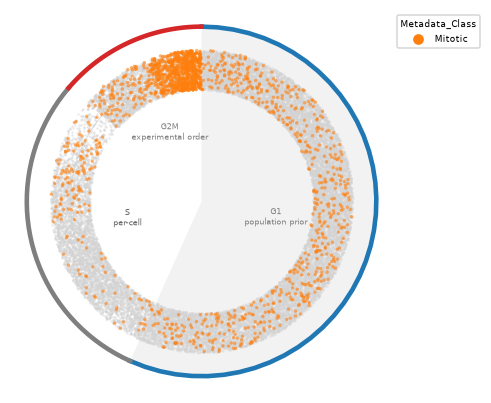

In [18]:
controls = cells[cells.obs["Metadata_Control_Type"] == "negcon"]
mt.pl.cell_cycle_clock(controls, color="Metadata_Class", groups=["Mitotic"])

Mitotic calls pile up at the late end of the G2M arc, just before division. Others spread over the G1 arc, where the
angle follows the prior, and some fall in S.

Across the knockouts, the order and the mitotic share disagree. The table gives, for each gene's G2M cells, the
median order, the share the classifier calls mitotic, and the median nuclear gamma-H2AX.

In [19]:
gh2ax = cells[:, "Nuclei_Intensity_MeanIntensity_GH2AX"].to_df().iloc[:, 0]
g2m_cells = cells.obs.loc[in_g2m]
pd.DataFrame(
    {
        "median order in G2M": g2m_cells.groupby("Metadata_Gene", observed=True)["cell_cycle_G2M_order"].median(),
        "share mitotic in G2M": mitotic[in_g2m].groupby(g2m_cells["Metadata_Gene"], observed=True).mean(),
        "median nuclear gamma-H2AX in G2M": gh2ax[in_g2m].groupby(g2m_cells["Metadata_Gene"], observed=True).median(),
    }
).sort_values("median order in G2M").round(3)

,median order in G2M,share mitotic in G2M,median nuclear gamma-H2AX in G2M
Metadata_Gene,,,
PSMB7,0.251,0.068,1414.047974
DTL,0.481,0.055,1730.063965
nontargeting,0.487,0.302,1722.130981
ITGAV,0.560,0.226,1810.863037
TLN1,0.586,0.332,1857.599976
HAUS6,0.619,0.637,1924.536987
SKA2,0.635,0.560,1932.307007
RRM1,0.713,0.087,2519.260986
SF3B3,0.860,0.277,2985.529053


SF3B3's G2M cells sit latest in the order, at a median of 0.86, yet 28% of them are mitotic, about as many as the
controls' 30% at 0.49. They carry the most gamma-H2AX. RRM1's G2M cells sit at 0.71 with 9% mitotic, and also carry
more gamma-H2AX than the controls. PSMB7's sit earliest, at 0.25, with the least gamma-H2AX. HAUS6 and SKA2, whose
G2M cells are 64% and 56% mitotic, sit at 0.62 and 0.64, later than the controls. Sorted by median order, the genes
are also sorted by gamma-H2AX, except that DTL and the controls swap, and the mitotic share follows no such order. Read it as progress only for knockouts that leave DNA damage alone, and check any
reading against the mitotic share.

Highlighting three of the knockouts on the clock, against a gray background of all the other cells, shows where each
one lands.

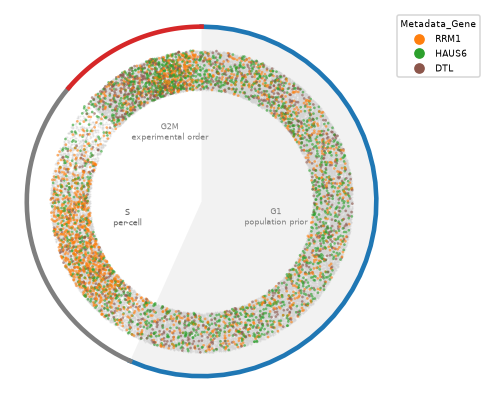

In [20]:
mt.pl.cell_cycle_clock(cells, color="Metadata_Gene", groups=["RRM1", "HAUS6", "DTL"])

Many of RRM1's cells sit on the S arc, and its G2M cells sit late in the order. HAUS6's G2M cells sit late as well,
as cells held in mitosis should. DTL's cells on the cycle lean toward G2M, and its largest effect, the cells above 4N,
is off the ring, since those cells have no position.

The classifier also splits each gene's G2M calls into G2 and mitosis (M), which suggests which knockouts hold cells in
mitosis and which before it. The split covers only cells called G2M. A quarter of the cells the classifier calls
mitotic are called G1 (second table), so the gains in M likely understate the change.

In [21]:
called = cells.obs["cell_cycle_phase"].astype(str)
split = called.where(called != "G2M", np.where(mitotic, "M", "G2"))
by_gene = pd.crosstab(cells.obs["Metadata_Gene"], split, normalize="index")[
    ["G1", "S", "G2", "M", "sub-2N", "above-4N"]
]
(by_gene - by_gene.loc["nontargeting"]).round(3)

cell_cycle_phase,G1,S,G2,M,sub-2N,above-4N
Metadata_Gene,,,,,,
DTL,-0.330,-0.082,0.087,-0.026,0.001,0.350
HAUS6,-0.137,0.011,-0.006,0.101,0.007,0.024
ITGAV,-0.027,0.020,0.006,-0.010,-0.000,0.012
PSMB7,-0.138,-0.009,0.155,-0.019,-0.001,0.011
RRM1,-0.321,0.278,0.055,-0.023,0.001,0.010
SF3B3,-0.112,-0.010,0.088,0.029,-0.001,0.005
SKA2,-0.133,0.005,0.015,0.090,0.001,0.021
TLN1,-0.033,0.007,0.015,0.013,-0.000,-0.001
nontargeting,0.000,0.000,0.000,0.000,0.000,0.000


In [22]:
pd.crosstab(cells.obs["cell_cycle_phase"], cells.obs["Metadata_Class"], normalize="columns").round(3)

Metadata_Class,Interphase,Mitotic
cell_cycle_phase,,
G1,0.645,0.248
S,0.213,0.137
G2M,0.113,0.505
sub-2N,0.003,0.016
above-4N,0.025,0.093


HAUS6 and SKA2 gain 10 and 9 percentage points of their cells in mitosis and almost none in G2, consistent with an
arrest in mitosis, as spindle defects predict. Both also gain about 2 points above 4N, as cells that leave a mitotic
arrest without dividing would. PSMB7 gains 16 points in G2 and has slightly fewer cells in mitosis than the controls,
and DTL gains 9 points in G2, consistent with an arrest before mitosis. For PSMB7 that matches only the G2 half of
the prediction. SF3B3 gains 9 points in G2 and 3 in mitosis. Half of the cells the classifier calls mitotic (51%) are
in G2M, and a quarter (25%) sit at 2N, possibly anaphase figures segmented as two nuclei, or classifier errors.

### Comparing knockouts as densities

Markers of several knockouts stack on top of each other on one clock. With ``kind="rings"``, each gene's cells on
the cycle become one smoothed density on its own ring, in the order of ``groups``, the first outermost.
``reference="nontargeting"`` adds the controls as the first ring, in gray, and draws their density as the dashed line
of every ring, so a knockout's excess in a phase shows where its ring rises above the dashed line. Because each
density sums to one, a rise in one arc comes with a dip elsewhere. Each density covers only the
gene's cells on the cycle, so it shows how they spread over the cycle, while the tables above give the shares
including the cells off it.

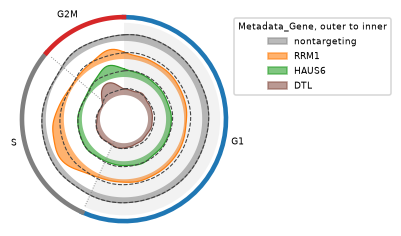

In [23]:
mt.pl.cell_cycle_clock(
    cells, kind="rings", color="Metadata_Gene", groups=["RRM1", "HAUS6", "DTL"], reference="nontargeting"
)

RRM1's ring rises above the controls through S, which is the gain in S the composition test found. HAUS6's rises
late in G2M, and DTL's rises in G2M as well. DTL's cells above 4N, its largest effect, are off the cycle and so not in
its ring. Since {func}`~mantispy.tl.phase_order` has run, the G2M arc follows the experimental order instead of the
prior, so where a density sits within G2M comes from that order, which here mostly tracks gamma-H2AX (see above).

To see every gene at once, ``groupby=`` draws one small clock per gene, each filled by phase, with the controls'
density as the dashed line and the controls' own clock first.

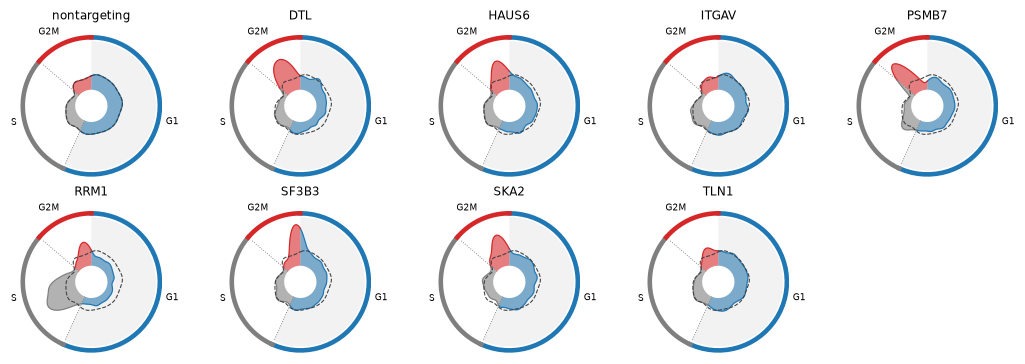

In [24]:
mt.pl.cell_cycle_clock(cells, kind="rings", groupby="Metadata_Gene", reference="nontargeting")

The small clocks sort the knockouts by eye. RRM1 is the only gene with a large bulge in S. PSMB7's G2M density sits
at the start of the arc, and SF3B3's and SKA2's toward its end, as their median G2M orders of 0.25, 0.86 and 0.64
in the table above say. ITGAV and TLN1 stay close to the dashed line, where their composition test found no
significant change. All clocks share one scale, so the area of a bulge compares across genes as a share of each
gene's cells on the cycle. DTL's G2M bulge leaves out its many cells above 4N, and the tables above give the shares
of all cells.

Rings get thin with many knockouts. ``kind="ridge"`` draws the same densities as rows over a straight cycle axis,
one row per gene, which stays readable for a whole screen.

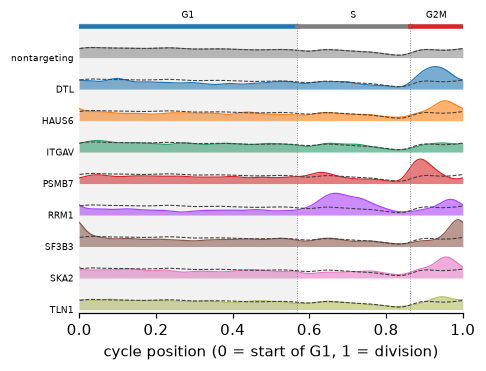

In [25]:
mt.pl.cell_cycle_clock(cells, kind="ridge", color="Metadata_Gene", reference="nontargeting")

The rows make the order within G2M easier to compare. PSMB7 peaks early in the G2M arc, DTL in its middle, and
HAUS6, SKA2 and SF3B3 late. For HAUS6 and SKA2, most of whose G2M cells are mitotic, late means close to division.
SF3B3's G2M cells are no more often mitotic than the controls' and carry the most gamma-H2AX, so its late peak
reflects DNA damage rather than progress. RRM1 peaks in the first half of S and again late in G2M, where it also
carries more gamma-H2AX than the controls.
Because the smoothing wraps across division, SF3B3's pile-up at the end of G2M also shows at the start of G1. Within
G1 the positions follow the prior, so the rows differ there mostly in height.

### DTL's nuclei above 4N

Merged nuclei and mitotic figures can also sit above 4N, and shape and the classifier together tell them from single
nuclei with extra DNA. Cells that died before imaging are missing altogether, so a knockout that kills its arrested
cells shows fewer of them than it made.

In [26]:
shape = cells[:, ["Nuclei_AreaShape_Area", "Nuclei_AreaShape_Solidity"]].to_df()
above = (cells.obs["cell_cycle_phase"] == "above-4N").to_numpy()
pd.DataFrame(
    {
        "nuclei above 4N": pd.Series(above).groupby(gene).sum(),
        "median area": shape.loc[above, "Nuclei_AreaShape_Area"].groupby(gene[above]).median(),
        "median solidity": shape.loc[above, "Nuclei_AreaShape_Solidity"].groupby(gene[above]).median(),
        "share irregular": (cells.obs.loc[above, "cell_cycle_qc"] == "irregular").groupby(gene[above]).mean(),
        "share mitotic": mitotic[above].groupby(gene[above]).mean(),
    }
).round(3)

,nuclei above 4N,median area,median solidity,share irregular,share mitotic
DTL,660,2660.5,0.980,0.014,0.005
HAUS6,69,2058.0,0.960,0.435,0.884
ITGAV,43,2163.0,0.963,0.442,0.302
PSMB7,42,2467.0,0.979,0.095,0.119
RRM1,40,2625.5,0.975,0.300,0.325
SF3B3,32,1916.5,0.967,0.375,0.531
SKA2,31,1913.0,0.965,0.323,0.677
TLN1,21,1939.0,0.966,0.333,0.429
nontargeting,261,1959.0,0.959,0.479,0.598


DTL's 660 nuclei above 4N look like single, large nuclei. Their median solidity is 0.980 and their median area
2,660 pixels, against 0.959 and 1,959 pixels for the controls' 261, and fewer than 1% of them are mitotic. The
controls' nuclei above 4N are mostly mitotic figures or merged nuclei, since 60% of them are mitotic and 48% are
irregular. So DTL's excess above 4N comes from single nuclei, as re-replication would produce, not from merged
nuclei.